# 1. Data
The data is present here: C:\Users\Adithya_Pattabhi\OneDrive - Dell Technologies\Desktop\python\jamboree_admission.csv

In [1]:
#Libraries to anlyze data
import pandas as pd
import numpy as np
from scipy import stats
import scipy.stats as sps

#libraries to visualize data
import matplotlib.pyplot as plt
import seaborn as sns

#libraries for models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error , mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso

import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 2. Data Loading

In [11]:
customer_df = pd.read_csv("jamboree_admission.csv")
df = customer_df.copy()
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [12]:
# The datatypes of the columns
print(df.info())
print('*************************************************\n')
print('*************************************************')
print(f'Shape of the dataset is {df.shape}')
print('*************************************************\n')
print('*************************************************')
print(f'Number of nan/null values in each column: \n{df.isna().sum()}')
print('*************************************************\n')
print('*************************************************')
print(f'Number of unique values in each column: \n{df.nunique()}')
print('*************************************************\n')
print('*************************************************')
print(f'Duplicate entries: \n{df.duplicated().value_counts()}')
print('*************************************************')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB
None
*************************************************

*************************************************
Shape of the dataset is (500, 9)
*************************************************

*************************************************
Number of nan/null values in each column: 
Serial No.           0
GRE Score  

In [13]:
df.columns

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR ', 'CGPA', 'Research', 'Chance of Admit '],
      dtype='object')

In [14]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,250.500000,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,144.481833,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,125.750000,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,250.500000,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,375.250000,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,500.000000,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


Data Insights:
- There are 500 unique applicants
- There are no null values
- There are no duplicates
- There is a space after LOR and Chance of Admit column name
- The column Serial No. can be dropped as it doesnt provide any additional information that what is provided by the dataframe's index.
- The GRE Score in the dataset ranges from 290 to 340 and hence can be converted to datatype int16
- The TOEFL Score in the dataset ranges from 92 to 120 and hence can be converted to datatype int16
- The University Rating in the dataset ranges from 1 to 5 and hence can be converted to datatype int16
- The SOP in the dataset ranges from 1 to 5 and hence can be converted to datatype float32
- The LOR in the dataset ranges from 1 to 5 and hence can be converted to datatype float32
- The CGPA in the dataset ranges from 6.8 to 9.92 and hence can be converted to datatype float32
- The Research in the dataset has values 0 and 1 and hence can be converted to datatype bool
- The Chance of Admit in the dataset ranges from 0.34 to 0.97 and hence can be converted to datatype float32

In [15]:
df.drop(columns="Serial No.", inplace=True)
df.rename(columns={"LOR ": "LOR", "Chance of Admit ": "Chance of Admit"}, inplace=True)
df["GRE Score"] = df["GRE Score"].astype("int16")
df["TOEFL Score"] = df["TOEFL Score"].astype("int16")
df["University Rating"] = df["University Rating"].astype("int16")
df["SOP"] = df["SOP"].astype("float32")
df["LOR"] = df["LOR"].astype("float32")
df["CGPA"] = df["CGPA"].astype("float32")
df["Research"] = df["Research"].astype("bool")
df["Chance of Admit"] = df["Chance of Admit"].astype("float32")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          500 non-null    int16  
 1   TOEFL Score        500 non-null    int16  
 2   University Rating  500 non-null    int16  
 3   SOP                500 non-null    float32
 4   LOR                500 non-null    float32
 5   CGPA               500 non-null    float32
 6   Research           500 non-null    bool   
 7   Chance of Admit    500 non-null    float32
dtypes: bool(1), float32(4), int16(3)
memory usage: 11.4 KB


In [16]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,True,0.92
1,324,107,4,4.0,4.5,8.87,True,0.76
2,316,104,3,3.0,3.5,8.00,True,0.72
3,322,110,3,3.5,2.5,8.67,True,0.80
4,314,103,2,2.0,3.0,8.21,False,0.65


In [20]:
print(f"Orignal data Memory usage: {customer_df.memory_usage(deep=True).sum()} bytes")
print(f"Data modeled Memory usage: {df.memory_usage(deep=True).sum()} bytes")

Orignal data Memory usage: 36132 bytes
Data modeled Memory usage: 11632 bytes


Insights:
- Original data memory usage: 36 KB and Modeled data memory usage: 12 KB i.e. reduced by 66.7%

# 3.EDA

## 3.1 Detecting Outliers

In [22]:
#helper function to detect outliers
def detectouliers(df):
    q1 = df.quantile(0.25)
    q3 = df.quantile(0.75)
    iqr = q3 - q1
    lower_bound = df[df < (q1 - 1.5 * iqr)]
    upper_bound = df[df > (q3 + 1.5 * iqr)]
    return lower_bound, upper_bound

In [28]:
numerical_columns = ["GRE Score", "TOEFL Score", "CGPA", "Chance of Admit"]
coulmn_outlier_dict = {}
for col in numerical_columns:
    print("*" * 50)
    print(f"Outliers of {col} are:")
    lower, upper  = detectouliers(df[col])
    if len(lower) > 0:
        print(f"Lower: {lower}")
    elif len(upper) > 0:
        print(f"Upper: {upper}")
    else:
        print("No outliers found")
    print("*" * 50)
    coulmn_outlier_dict[col] = {"lower": lower, "upper": upper}

**************************************************
Outliers of GRE Score are:
No outliers found
**************************************************
**************************************************
Outliers of TOEFL Score are:
No outliers found
**************************************************
**************************************************
Outliers of CGPA are:
No outliers found
**************************************************
**************************************************
Outliers of Chance of Admit are:
Lower: 92     0.34
376    0.34
Name: Chance of Admit, dtype: float32
**************************************************


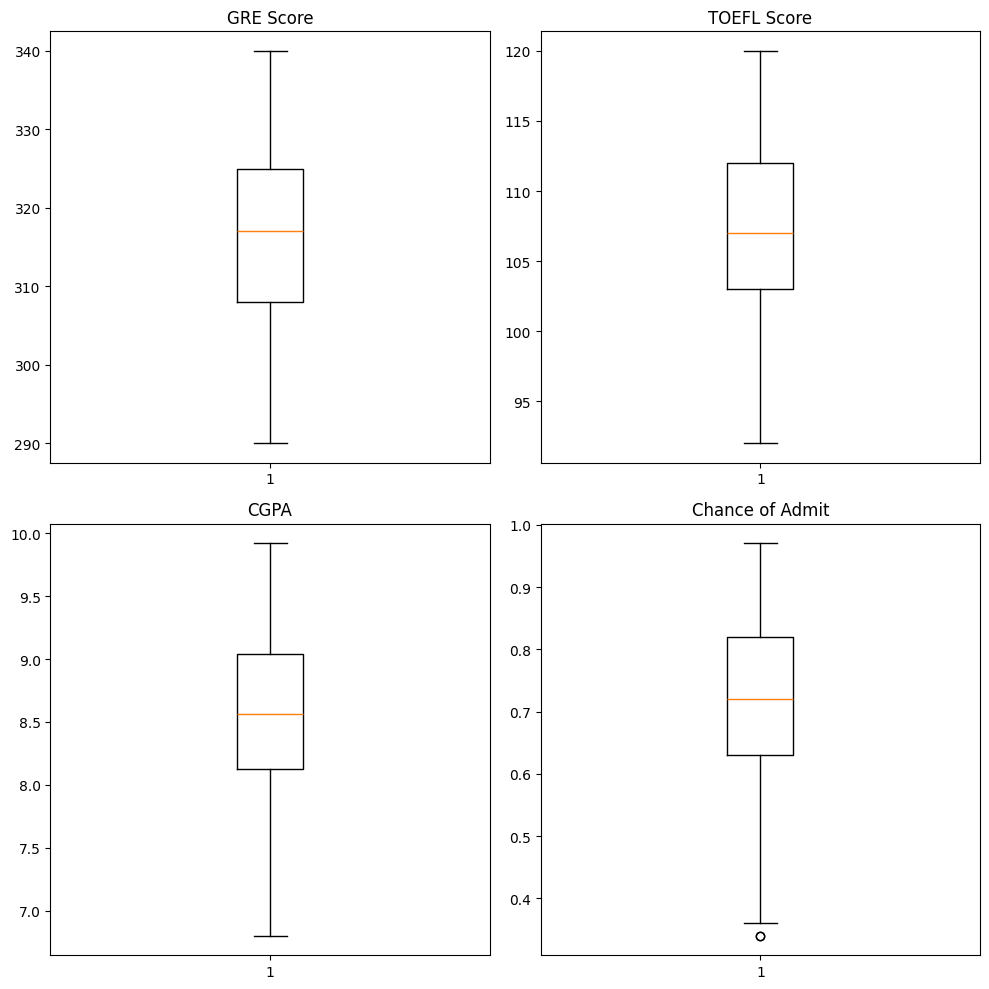

In [29]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for idx, col in enumerate(numerical_columns):
    row = idx // 2
    col_idx = idx % 2
    axs[row, col_idx].boxplot(df[col])
    axs[row, col_idx].set_title(col)
 
plt.tight_layout()
plt.show()

In [30]:
print(coulmn_outlier_dict)

{'GRE Score': {'lower': Series([], Name: GRE Score, dtype: int16), 'upper': Series([], Name: GRE Score, dtype: int16)}, 'TOEFL Score': {'lower': Series([], Name: TOEFL Score, dtype: int16), 'upper': Series([], Name: TOEFL Score, dtype: int16)}, 'CGPA': {'lower': Series([], Name: CGPA, dtype: float32), 'upper': Series([], Name: CGPA, dtype: float32)}, 'Chance of Admit': {'lower': 92     0.34
376    0.34
Name: Chance of Admit, dtype: float32, 'upper': Series([], Name: Chance of Admit, dtype: float32)}}


In [31]:
for key, value in coulmn_outlier_dict.items():
    lower_count = len(value['lower'])
    upper_count = len(value['upper'])
    total_outliers = lower_count + upper_count
    print(f"The column {key} has {total_outliers} outliers (lower: {lower_count}, upper: {upper_count})")

The column GRE Score has 0 outliers (lower: 0, upper: 0)
The column TOEFL Score has 0 outliers (lower: 0, upper: 0)
The column CGPA has 0 outliers (lower: 0, upper: 0)
The column Chance of Admit has 2 outliers (lower: 2, upper: 0)


Insights:
- Chance of Admit has 2 outliers
- All other columns have 0 outliers
- Only 2 outliers out of 500 data points (0.4%) - negligible. Hence not removing any outliers.

# 3.2 Univariate Analysis

# 3.2.1 Numerical Features

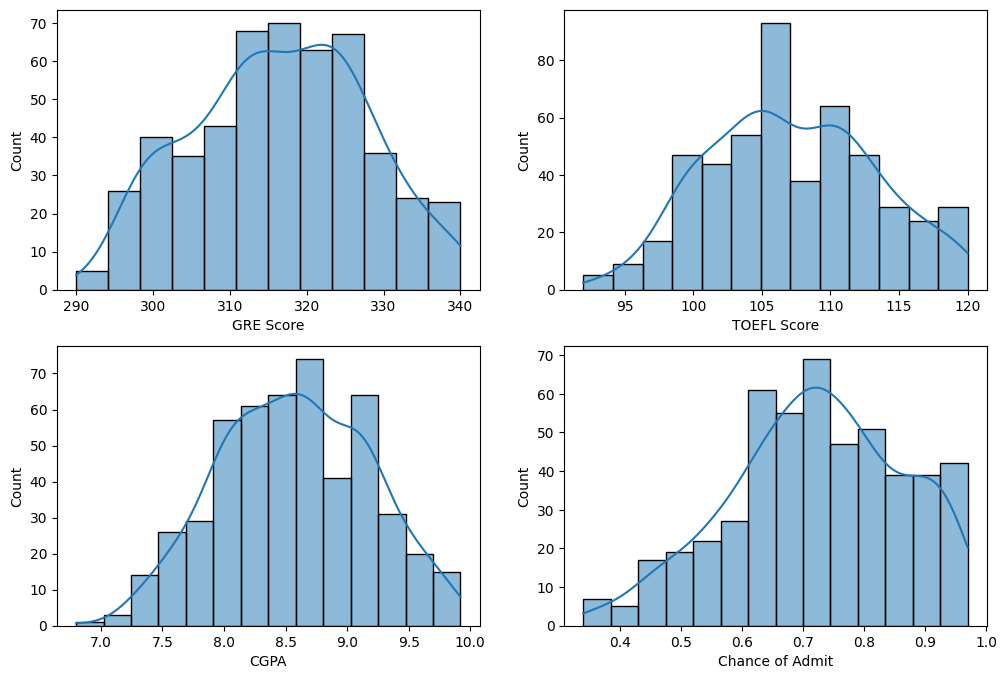

In [32]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize = (12, 8))
sns.histplot(data=df, x = "GRE Score", kde=True, ax=axes[0,0])
sns.histplot(data=df, x = "TOEFL Score", kde=True, ax=axes[0,1])
sns.histplot(data=df, x = "CGPA", kde=True, ax=axes[1,0])
sns.histplot(data=df, x = "Chance of Admit", kde=True, ax=axes[1,1])
plt.show()

# 3.2.2 Categorical Features

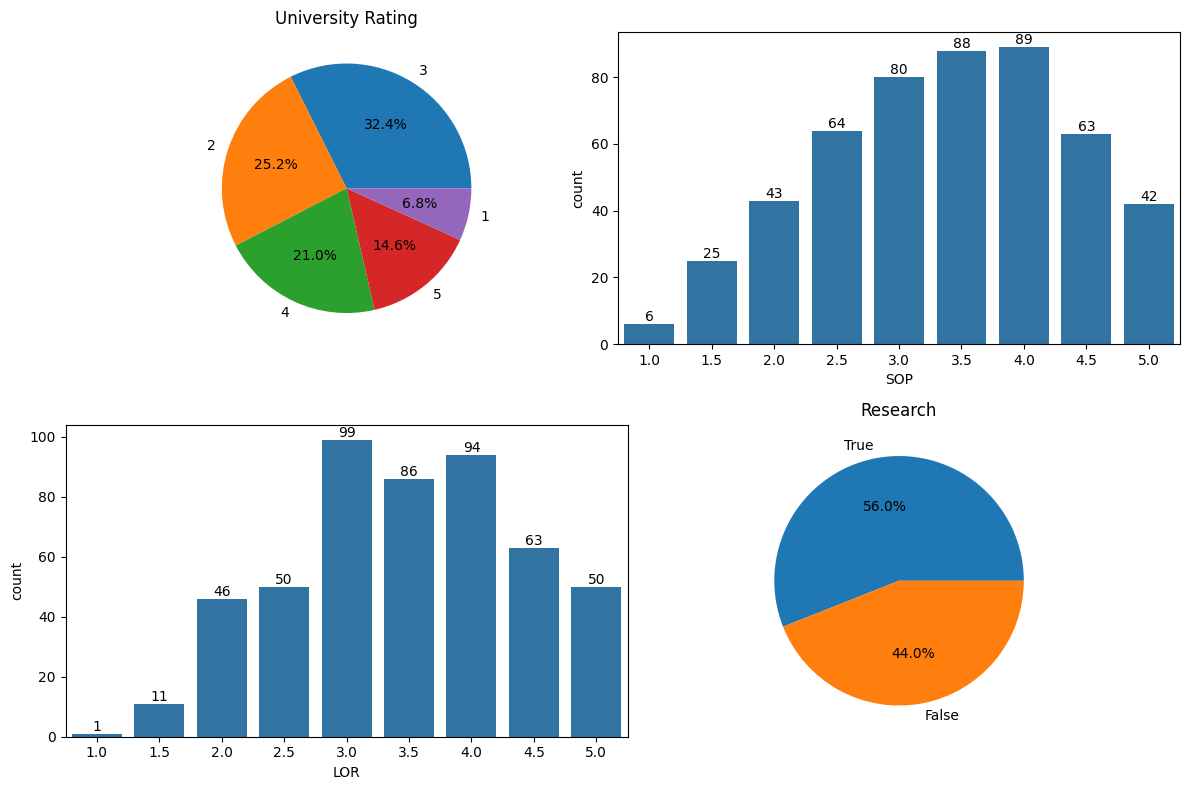

In [35]:
categorical_columns = ['University Rating', 'SOP', 'LOR', 'Research']
fig, axes = plt.subplots(2,2,figsize=(12,8))
data = df["University Rating"].value_counts()
axes[0,0].pie(data.values, labels=data.index, autopct='%1.1f%%')
axes[0,0].set_title('University Rating')
ax = sns.countplot(x='SOP', data=df, ax=axes[0,1])
ax.bar_label(ax.containers[0])
ax = sns.countplot(x='LOR', data=df, ax=axes[1,0])
ax.bar_label(ax.containers[0])
axes[1,1].pie(df['Research'].value_counts().values, labels=df['Research'].value_counts().index, autopct='%.1f%%')
axes[1,1].set_title('Research')
fig.tight_layout()
plt.show()

Insights:

**University Rating (pie chart):**
- Most applicants have university ratings of 3 and 4, indicating a concentration of students from mid-to-high rated institutions.

**SOP (countplot):**
- Statement of Purpose scores are fairly evenly distributed across 1.5 to 4.5, with slight peaks at 3.0 and 4.0, suggesting balanced quality in application essays.

**LOR (countplot):**
- Letter of Recommendation scores show a right-skewed distribution with higher concentration at 3.0 and above, indicating generally strong recommendation letters.

**Research (pie chart):**
- Only 56% of applicants have research experience, suggesting nearly half of the candidates lack formal research background.

# 3.3 Bivariate Analysis

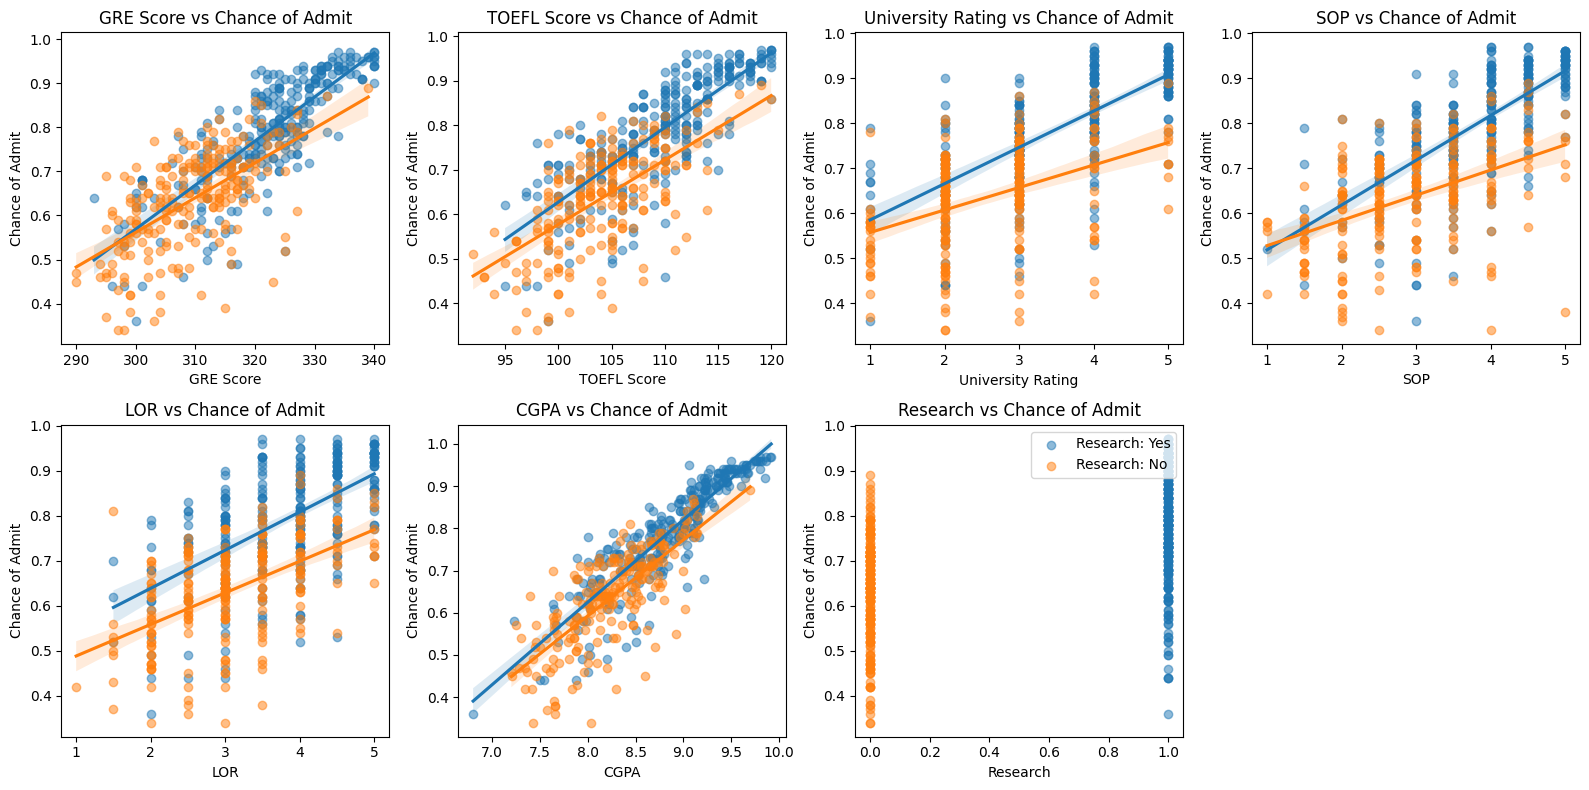

In [42]:
x_vars = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

colors = {True: '#1f77b4', False: '#ff7f0e'}  # Blue for Research=True, Orange for Research=False

for idx, col in enumerate(x_vars):
    # Plot Research=True (Yes)
    data_yes = df[df['Research'] == 1]
    sns.regplot(data=data_yes, x=col, y='Chance of Admit', ax=axes[idx], 
                scatter_kws={'alpha':0.5, 'color': colors[True]}, 
                line_kws={'color': colors[True]}, label='Research: Yes')
    
    # Plot Research=False (No)
    data_no = df[df['Research'] == 0]
    sns.regplot(data=data_no, x=col, y='Chance of Admit', ax=axes[idx], 
                scatter_kws={'alpha':0.5, 'color': colors[False]}, 
                line_kws={'color': colors[False]}, label='Research: No')
    
    axes[idx].set_title(f'{col} vs Chance of Admit')

# Hide empty subplots
for idx in range(len(x_vars), 8):
    axes[idx].axis('off')

# Add legend to the last visible subplot (axes[6] - 2nd row, 3rd column)
axes[6].legend(loc='upper right', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

Bivariate Analysis Insights

**Research Experience Impact:**
- Applicants with research experience (blue) consistently show higher chances of admission across all features
- The regression line for Research=Yes is generally steeper and positioned higher than Research=No
- Research experience appears to be a strong differentiator in admission decisions

**GRE & TOEFL Scores:**
- Research applicants tend to have higher GRE and TOEFL scores, which correlates with better admission chances
- The positive relationship between GRE/TOEFL scores and Chance of Admit is more pronounced for research applicants
- Non-research applicants with high GRE/TOEFL scores still show competitive admission chances

**University Rating & Research:**
- Interestingly, applicants from middle-rated universities (Rating 3-4) without research experience still demonstrate reasonable admission chances
- This suggests that while research is beneficial, it is not the sole determining factor
- Strong academic performance (CGPA) and good SOP/LOR scores can compensate for lack of research experience

**CGPA and SOP/LOR:**
- Higher CGPA consistently correlates with better admission chances regardless of research status
- SOP and LOR scores show positive relationships with admission probability for both groups
- The gap between research and non-research applicants narrows when other metrics (CGPA, SOP, LOR) are strong

**Overall Pattern:**
- Research experience provides a significant advantage, especially when combined with strong academic metrics
- However, the data shows that non-research applicants can still achieve good admission chances through excellent GRE/TOEFL scores, high CGPA, and strong recommendation letters
- Admissions appear to be holistic, considering multiple factors rather than research alone

# 3.4 Multivariate Analysis

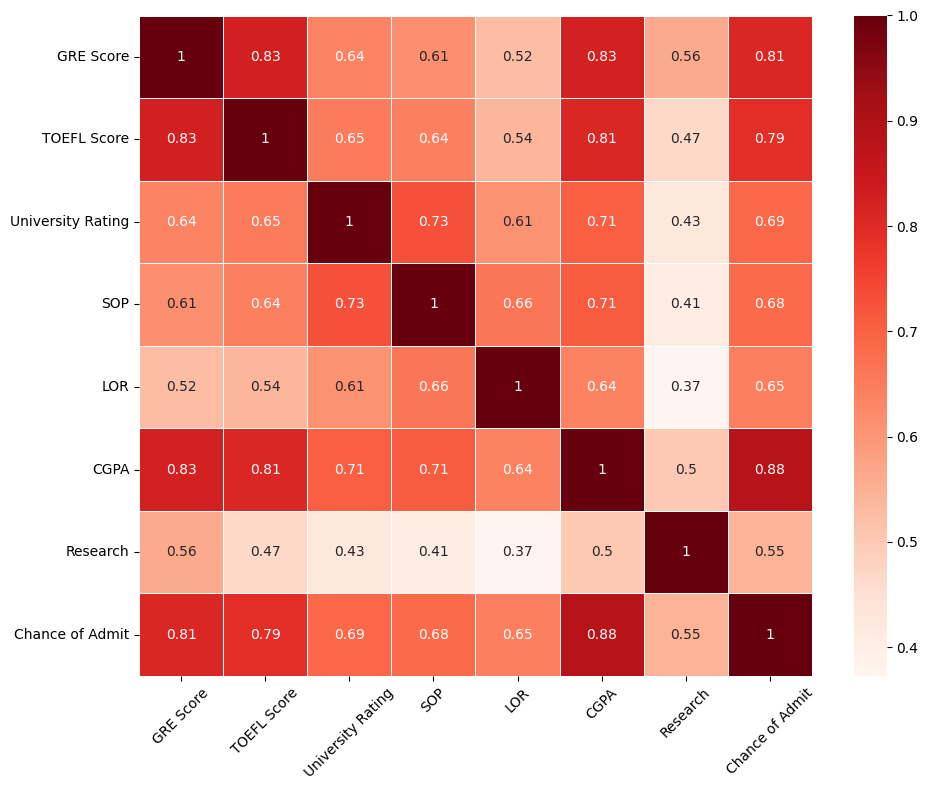

In [46]:
fig, ax  = plt.subplots(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, linewidth=0.5, cmap = "Reds", ax=ax)
ax.xaxis.tick_bottom()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()